# DS3000 Assignment 8

#### name: Muyuan Ma
#### date: March 5th, 2023

#### Problem 1: Load and inspect the data

In [1]:
# import all python tools that will be used
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import ols
from sklearn.linear_model import LinearRegression

In [2]:
#load data from the given url using panda read_csv
annual_meat_consumption_df = pd.read_csv(\
"https://stats.oecd.org/sdmx-json/data/DP_LIVE/.MEATCONSUMP.../OECD?contentType=csv&detail=code&separator=comma&csv-lang=en")

In [3]:
# inspect the data by seeing its first five data
print(annual_meat_consumption_df.head())

  LOCATION    INDICATOR SUBJECT MEASURE FREQUENCY  TIME   Value  Flag Codes
0      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1990   0.000         NaN
1      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1991  27.942         NaN
2      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1992  26.405         NaN
3      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1993  26.370         NaN
4      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1994  25.662         NaN


In [4]:
# check the data type of each column
print(annual_meat_consumption_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12160 entries, 0 to 12159
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   LOCATION    12160 non-null  object 
 1   INDICATOR   12160 non-null  object 
 2   SUBJECT     12160 non-null  object 
 3   MEASURE     12160 non-null  object 
 4   FREQUENCY   12160 non-null  object 
 5   TIME        12160 non-null  int64  
 6   Value       12160 non-null  float64
 7   Flag Codes  0 non-null      float64
dtypes: float64(2), int64(1), object(5)
memory usage: 760.1+ KB
None


In [5]:
# check the dimension of the dataframe
print(annual_meat_consumption_df.shape)

(12160, 8)


In [6]:
# check the number of null number of from the dataframe
print(annual_meat_consumption_df.isnull().sum())

LOCATION          0
INDICATOR         0
SUBJECT           0
MEASURE           0
FREQUENCY         0
TIME              0
Value             0
Flag Codes    12160
dtype: int64


Since none of Flag Code is valid(every data is null), I decide to delete the whole column of Flag Codes.

In [7]:
# drop the Flag Codes column
annual_meat_consumption_df = annual_meat_consumption_df.drop(['Flag Codes'], axis=1)

LOCATION, INDICATOR, SUBJECT, MEASURE, and FREQUENCY should all be String data type, so I modify these columns' data type to String 

In [8]:
# change LOCATION's data type to string
annual_meat_consumption_df['LOCATION'] = annual_meat_consumption_df['LOCATION'].astype('string')
# change INDICATOR's data type to string
annual_meat_consumption_df['INDICATOR'] = annual_meat_consumption_df['INDICATOR'].astype('string')
# change SUBJECT's data type to string
annual_meat_consumption_df['SUBJECT'] = annual_meat_consumption_df['SUBJECT'].astype('string')
# change MEASURE's data type to string
annual_meat_consumption_df['MEASURE'] = annual_meat_consumption_df['MEASURE'].astype('string')
# change FREQUENCY's data type to string
annual_meat_consumption_df['FREQUENCY'] = annual_meat_consumption_df['FREQUENCY'].astype('string')

In [9]:
# then check whether the column has been droped by using info method 
# and whether every data is in their appropriate data type 
print(annual_meat_consumption_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12160 entries, 0 to 12159
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   LOCATION   12160 non-null  string 
 1   INDICATOR  12160 non-null  string 
 2   SUBJECT    12160 non-null  string 
 3   MEASURE    12160 non-null  string 
 4   FREQUENCY  12160 non-null  string 
 5   TIME       12160 non-null  int64  
 6   Value      12160 non-null  float64
dtypes: float64(1), int64(1), string(5)
memory usage: 665.1 KB
None


In [10]:
# finally check whether any other null data was left in the data frame
print(annual_meat_consumption_df.isnull().sum())

LOCATION     0
INDICATOR    0
SUBJECT      0
MEASURE      0
FREQUENCY    0
TIME         0
Value        0
dtype: int64


#### Problem 2: Extract the meat consumption data for any two countries of your choice, then evaluate the patterns and trends in their meat consumption.

First, I need to check what are countries' data are avaliable in this data frame, and what are the abbreviations of these countries' names.

In [11]:
# check which countries are avaliable from the dataframe
print(annual_meat_consumption_df['LOCATION'].value_counts(dropna=False))

AUS      320
ARG      320
IRN      320
JPN      320
KOR      320
MEX      320
NZL      320
TUR      320
USA      320
BRA      320
ZAF      320
CHL      320
CHN      320
COL      320
EGY      320
ETH      320
IND      320
IDN      320
ISR      320
KAZ      320
MYS      320
CHE      320
NGA      320
PAK      320
PRY      320
PER      320
PHL      320
RUS      320
SAU      320
THA      320
CAN      320
UKR      320
VNM      320
WLD      320
OECD     320
BRICS    320
NOR      320
GBR      320
Name: LOCATION, dtype: Int64


I choose to extract meat consumption data from Canada and Australia. I choose to explore beef and poultry for each of the two countries I previously mentioned.

### For Canada's Data Analysis

In [12]:
# build a dataframe that store the meat consumption data in Canada
canada_annual_meat_consumption_df = \
annual_meat_consumption_df[annual_meat_consumption_df['LOCATION'] == 'CAN']

In [13]:
# check the head of the dataframe
print(canada_annual_meat_consumption_df.head())

    LOCATION    INDICATOR SUBJECT MEASURE FREQUENCY  TIME   Value
160      CAN  MEATCONSUMP    BEEF  KG_CAP         A  1990  25.002
161      CAN  MEATCONSUMP    BEEF  KG_CAP         A  1991  24.456
162      CAN  MEATCONSUMP    BEEF  KG_CAP         A  1992  23.830
163      CAN  MEATCONSUMP    BEEF  KG_CAP         A  1993  22.805
164      CAN  MEATCONSUMP    BEEF  KG_CAP         A  1994  23.226


In [14]:
# build a dataframe that only store beef consumption data in Canada
canada_annual_beef_consumption_df = \
canada_annual_meat_consumption_df[canada_annual_meat_consumption_df['SUBJECT'] == 'BEEF']

In [15]:
# check the dataframe of canadian beef consumption by seeing its head
print(canada_annual_beef_consumption_df.head())

    LOCATION    INDICATOR SUBJECT MEASURE FREQUENCY  TIME   Value
160      CAN  MEATCONSUMP    BEEF  KG_CAP         A  1990  25.002
161      CAN  MEATCONSUMP    BEEF  KG_CAP         A  1991  24.456
162      CAN  MEATCONSUMP    BEEF  KG_CAP         A  1992  23.830
163      CAN  MEATCONSUMP    BEEF  KG_CAP         A  1993  22.805
164      CAN  MEATCONSUMP    BEEF  KG_CAP         A  1994  23.226


In [16]:
# build a dataframe that only store poultry consumption data in Canada
canada_annual_poultry_consumption_df = \
canada_annual_meat_consumption_df[canada_annual_meat_consumption_df['SUBJECT'] == 'POULTRY']

In [17]:
# check the number of data in each measure unit in canadian beef consumption dataframe
# make sure it 
print(canada_annual_beef_consumption_df['MEASURE'].value_counts(dropna=False))

KG_CAP        40
THND_TONNE    40
Name: MEASURE, dtype: Int64


In [18]:
# check the number of data in each measure unit in canadian beef consumption dataframe
print(canada_annual_poultry_consumption_df['MEASURE'].value_counts(dropna=False))

KG_CAP        40
THND_TONNE    40
Name: MEASURE, dtype: Int64


I select kilograms of retail weight per capita as unit of measurement

In [19]:
# filter the beef dataframe, let the only data measured by 
# kilograms of retail weight per capita as unit of measurement left
canada_annual_beef_consumption_df =\
canada_annual_beef_consumption_df[canada_annual_beef_consumption_df['MEASURE'] == 'KG_CAP']

In [20]:
# filter the poultry dataframe, let the only data measured by
# kilograms of retail weight per capita as unit of measurement left
canada_annual_poultry_consumption_df =\
canada_annual_poultry_consumption_df[canada_annual_poultry_consumption_df['MEASURE'] == 'KG_CAP']

Because line chart can represent the trend and changes of data over a period of time, so I visualize the data in a line chart 

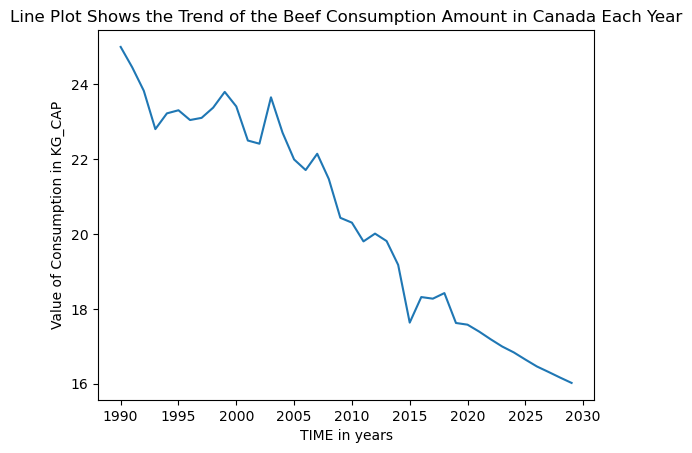

In [21]:
# visualize the value of consumption of beef in Canada
# each year in kilograms of 
# retail weight per capita as unit of measurement
# by making a line plot using the year as x value and value of consumption as
# y value for analyzing the trending of consumption amount 
sns.lineplot(x = 'TIME', y = 'Value', data=canada_annual_beef_consumption_df,ci=None)\
.set(xlabel = "TIME in years", ylabel = "Value of Consumption in KG_CAP",\
     title = "Line Plot Shows the Trend of \
the Beef Consumption Amount in Canada Each Year")
plt.show()

The line chart above shows out that there's a decreasing trending with a little bit of fluctuatoing pattern for beef consumption amount in Canada for each year.

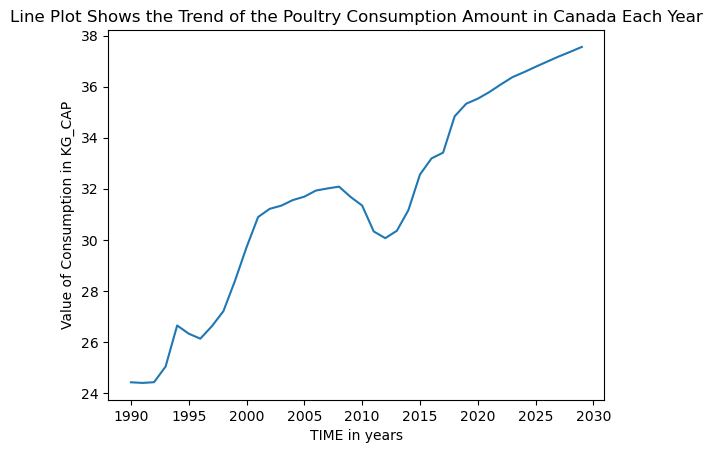

In [22]:
# visualize the value of consumption of poultry in Canada
# each year in kilograms of 
# retail weight per capita as unit of measurement
# by making a line plot using the year as x value and value of consumption as
# y value for analyzing the trending of consumption amount 
sns.lineplot(x = 'TIME', y = 'Value', data=canada_annual_poultry_consumption_df,ci=None)\
.set(xlabel = "TIME in years", ylabel = "Value of Consumption in KG_CAP",\
     title = "Line Plot Shows the Trend of \
the Poultry Consumption Amount in Canada Each Year")
plt.show()

The line chart above shows out that there's an increasing trending with some fluctuating pattern for poultry consumption amount in Canada for each year.

### For Australia's Data Analysis

In [23]:
# build a dataframe that store the meat consumption data in Australia
australia_annual_meat_consumption_df = \
annual_meat_consumption_df[annual_meat_consumption_df['LOCATION'] == 'AUS']

In [24]:
# check the head of the dataframe
print(australia_annual_meat_consumption_df.head())

  LOCATION    INDICATOR SUBJECT MEASURE FREQUENCY  TIME   Value
0      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1990   0.000
1      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1991  27.942
2      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1992  26.405
3      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1993  26.370
4      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1994  25.662


In [25]:
# build a dataframe that only stores beef consumption in Australia each year
australia_annual_beef_consumption_df = \
australia_annual_meat_consumption_df[australia_annual_meat_consumption_df['SUBJECT'] == 'BEEF']

In [26]:
# check the head of the newly builded dataframe
print(australia_annual_beef_consumption_df.head())

  LOCATION    INDICATOR SUBJECT MEASURE FREQUENCY  TIME   Value
0      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1990   0.000
1      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1991  27.942
2      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1992  26.405
3      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1993  26.370
4      AUS  MEATCONSUMP    BEEF  KG_CAP         A  1994  25.662


In [27]:
# build a dataframe that only stores poultry consumption in Australia each year
australia_annual_poultry_consumption_df = \
australia_annual_meat_consumption_df[australia_annual_meat_consumption_df['SUBJECT'] == 'POULTRY']

In [28]:
# check the head of the newly builded dataframe
print(australia_annual_poultry_consumption_df.head())

   LOCATION    INDICATOR  SUBJECT MEASURE FREQUENCY  TIME   Value
80      AUS  MEATCONSUMP  POULTRY  KG_CAP         A  1990  22.051
81      AUS  MEATCONSUMP  POULTRY  KG_CAP         A  1991  22.350
82      AUS  MEATCONSUMP  POULTRY  KG_CAP         A  1992  22.436
83      AUS  MEATCONSUMP  POULTRY  KG_CAP         A  1993  23.807
84      AUS  MEATCONSUMP  POULTRY  KG_CAP         A  1994  24.473


In [29]:
# check the number of data in each measure unit in Australian beef consumption dataframe
# make sure it 
print(australia_annual_beef_consumption_df['MEASURE'].value_counts(dropna=False))

KG_CAP        40
THND_TONNE    40
Name: MEASURE, dtype: Int64


In [30]:
# check the number of data in each measure unit in Australian poultry consumption dataframe
# make sure it 
print(australia_annual_poultry_consumption_df['MEASURE'].value_counts(dropna=False))

KG_CAP        40
THND_TONNE    40
Name: MEASURE, dtype: Int64


I select kilograms of retail weight per capita as unit of measurement

In [31]:
# filter the beef dataframe, let the only data measured by 
# kilograms of retail weight per capita as unit of measurement left
australia_annual_beef_consumption_df =\
australia_annual_beef_consumption_df[australia_annual_beef_consumption_df['MEASURE'] == 'KG_CAP']

In [32]:
# check the filtered data type, make sure only KG_CAP Measure left
print(australia_annual_beef_consumption_df['MEASURE'].value_counts(dropna=False))

KG_CAP    40
Name: MEASURE, dtype: Int64


In [33]:
# filter the poultry dataframe, let the only data measured by
# kilograms of retail weight per capita as unit of measurement left
australia_annual_poultry_consumption_df =\
australia_annual_poultry_consumption_df[australia_annual_poultry_consumption_df['MEASURE'] == 'KG_CAP']

In [34]:
# check the filtered data type, make sure only KG_CAP Measure left
print(australia_annual_poultry_consumption_df['MEASURE'].value_counts(dropna=False))

KG_CAP    40
Name: MEASURE, dtype: Int64


Because line chart can represent the trend and changes of data over a period of time, so I visualize the data in a line chart 

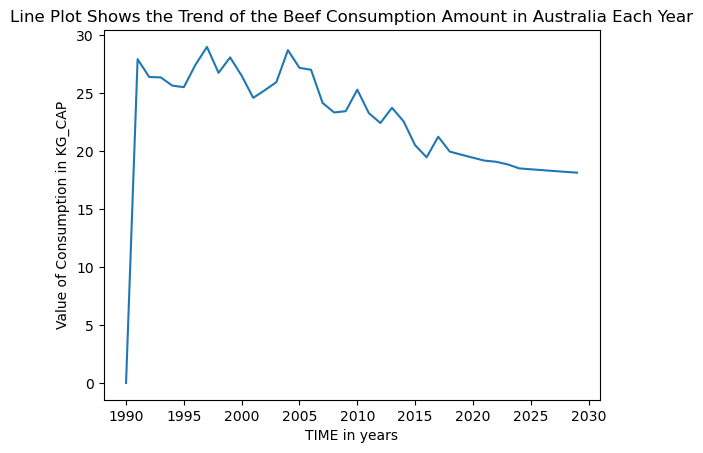

In [35]:
# visualize the value of consumption of beef in Australia
# each year in kilograms of 
# retail weight per capita as unit of measurement
# by making a line plot using the year as x value and value of consumption as
# y value for analyzing the trending of consumption amount 
sns.lineplot(x = 'TIME', y = 'Value', data=australia_annual_beef_consumption_df,ci=None)\
.set(xlabel = "TIME in years", ylabel = "Value of Consumption in KG_CAP",\
     title = "Line Plot Shows the Trend of \
the Beef Consumption Amount in Australia Each Year")
plt.show()

The line chart above shows out that the data start with a 0 in 1990, but later increase to a reasonable point in the next year. The data of the amount of beef consumption in Australia each year has a trend of decrease with fluctuation pattern after 1991. 
I think that 1990 is an invalid data point and should be removed. I re-visualize a line plot after removing the 1990 point.

In [36]:
# remove the data row in 1990
australia_annual_beef_consumption_df = \
australia_annual_beef_consumption_df[australia_annual_beef_consumption_df['TIME'] > 1990]

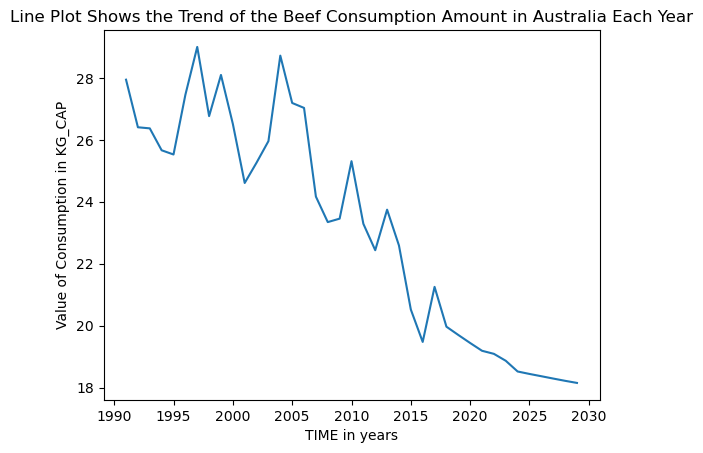

In [37]:
# re-visualize the line plot again
sns.lineplot(x = 'TIME', y = 'Value', data=australia_annual_beef_consumption_df,ci=None)\
.set(xlabel = "TIME in years", ylabel = "Value of Consumption in KG_CAP",\
     title = "Line Plot Shows the Trend of \
the Beef Consumption Amount in Australia Each Year")
plt.show()

This plot looks perfect now. Now the amount of beef consumption in Australia each year has a trend of decrease with very large and obious fluctuating pattern.

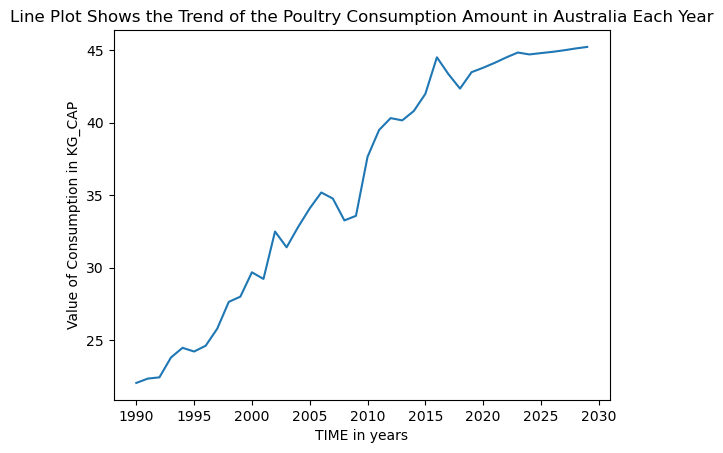

In [38]:
# visualize the value of consumption of poultry in Australia
# each year in kilograms of 
# retail weight per capita as unit of measurement
# by making a line plot using the year as x value and value of consumption as
# y value for analyzing the trending of consumption amount 
sns.lineplot(x = 'TIME', y = 'Value', data=australia_annual_poultry_consumption_df,ci=None)\
.set(xlabel = "TIME in years", ylabel = "Value of Consumption in KG_CAP",\
     title = "Line Plot Shows the Trend of \
the Poultry Consumption Amount in Australia Each Year")
plt.show()

The line plot above shows out that the data of the amount of poultry consumption in Australia each year has a trend of increase with a little bit of fluctuating pattern.

#### Problem 3: Extract the poultry consumption data, from 1994 to 2014 (inclusive), for South Africa, that is measured in thousand tonnes of carcass weight

In [39]:
# build a new dataframe that store only poultry consumption data from 1994 to 2014 in South Africa
# measured in tousand tonnes of carcass weight
sa_poultry_consumption_in_THND_TONNE_df = \
annual_meat_consumption_df[(annual_meat_consumption_df['LOCATION'] == 'ZAF') &\
                          (annual_meat_consumption_df['SUBJECT'] == 'POULTRY') &\
                          (annual_meat_consumption_df['TIME'] >= 1994) &\
                          (annual_meat_consumption_df['TIME'] <= 2014) &\
                          (annual_meat_consumption_df['MEASURE'] == 'THND_TONNE')]
                          

In [40]:
# check the dataframe by see its head
print(sa_poultry_consumption_in_THND_TONNE_df.head())

     LOCATION    INDICATOR  SUBJECT     MEASURE FREQUENCY  TIME    Value
6444      ZAF  MEATCONSUMP  POULTRY  THND_TONNE         A  1994  628.900
6445      ZAF  MEATCONSUMP  POULTRY  THND_TONNE         A  1995  709.422
6446      ZAF  MEATCONSUMP  POULTRY  THND_TONNE         A  1996  710.258
6447      ZAF  MEATCONSUMP  POULTRY  THND_TONNE         A  1997  780.825
6448      ZAF  MEATCONSUMP  POULTRY  THND_TONNE         A  1998  725.003


The above first 5 head outputs show that the time is started from 1994

In [41]:
# check the dataframe by sort the dataframe by time in descending order and see its head
print(sa_poultry_consumption_in_THND_TONNE_df.tail())

     LOCATION    INDICATOR  SUBJECT     MEASURE FREQUENCY  TIME     Value
6460      ZAF  MEATCONSUMP  POULTRY  THND_TONNE         A  2010  1671.001
6461      ZAF  MEATCONSUMP  POULTRY  THND_TONNE         A  2011  1772.399
6462      ZAF  MEATCONSUMP  POULTRY  THND_TONNE         A  2012  1829.434
6463      ZAF  MEATCONSUMP  POULTRY  THND_TONNE         A  2013  2009.806
6464      ZAF  MEATCONSUMP  POULTRY  THND_TONNE         A  2014  2113.786


The above first 5 head outputs show that the time is ended with 2014

In [42]:
# check the dimension of the data
print(sa_poultry_consumption_in_THND_TONNE_df.shape)

(21, 7)


The above head and tail check certify that the dataframe only contain the necessary data and satisfy each condition mentioned by the question.

#### Problem 4: Summarize the extracted data using descriptive statistics. Explain the summary.

In this problem, I would like to only analyze the frequency for INDICATOR and FREQUENCY column, the measure of central tendency and dispersion for Value column. 
Other columns are not worth to analyze since LOCATION, SUBJECT, and MEASURE are all the same, and TIME are always with the difference of 1. 

###### Measure the Central Tendency

For identifying its central tendency, I would like to first calculate the mean and median for the Value column, then compare the mean and median value. 
If the mean is greater than the median, it has a positive skew
If the mean is less than the median, it has a negative skew
If the mean equals to the median, it has a symmetrical distribution

In [43]:
# calculate the mean of Value column in dataframe
mean_value = sa_poultry_consumption_in_THND_TONNE_df['Value'].mean() # the mean Value of poultry consmption amount
round_mean_value = round(mean_value, 2) # round to 2 digits
print('mean value: ' + str(round_mean_value))

mean value: 1224.01


In [44]:
# calculate the median of Value column in dataframe
median_value = sa_poultry_consumption_in_THND_TONNE_df['Value'].median() # the median Value of poultry consmption amount
round_median_value = round(median_value, 2) # round to 2 digits
print('median value: ' + str(round_median_value))

median value: 1084.41


In [45]:
# comparing the mean and median value to identify the central tendency
if (mean_value > median_value):
    print('There is a positive skew for the Value column of the dataframe')
elif (mean_value < median_value):
    print('There is a negative skew for the Value column of the dataframe')
else:
    print('There is a symmetrical distribution of data for the Value column of the dataframe')

There is a positive skew for the Value column of the dataframe


Thus, I conclude that the distribution of the Value column(series of the amount of poultry consumed in South Africa between 1994 and 2014 measured in tousand tonnes of carcass weight for each year) has a positive skew. Its peak is on the left. 
This indicates it tends to have more data points below the average appear in the Value column of the dataframe than data points above the average.

### Measure the dispersion

##### Range Calculation

In [46]:
# calcualte the range of the Value column in dataframe
value_range = sa_poultry_consumption_in_THND_TONNE_df['Value'].max() -\
sa_poultry_consumption_in_THND_TONNE_df['Value'].min()
round_value_range = round(value_range, 2)
print('The range is: ' + str(round_value_range))

The range is: 1484.89


The Value column has a range of 1494.89.

##### Variance Calculation

In [47]:
# calculate the variance of the Value column in dataframe
value_variance = sa_poultry_consumption_in_THND_TONNE_df['Value'].var()
print('The Variance is:', round(value_variance, 2))

The Variance is: 217357.55


In [48]:
# calculate the standard deviation of the Value column in dataframe
value_standard_deviation =\
sa_poultry_consumption_in_THND_TONNE_df['Value'].std()
print('The Standard Deviation is: ', round(value_standard_deviation, 2))

The Standard Deviation is:  466.22


The Value column has a variance of 217357.55 and a standard deviation of 466.22. This large variance and standard deviation indicate that the data in Value column for this dataframe seperate in a very large scale.

### Frequency

In [49]:
print('The frequency is: ', sa_poultry_consumption_in_THND_TONNE_df['INDICATOR'].count())
print('The frequency for each INDICATOR: \n', sa_poultry_consumption_in_THND_TONNE_df['INDICATOR'].value_counts())
print('The number of unique INDICATOR(s) in the data: ', sa_poultry_consumption_in_THND_TONNE_df['INDICATOR'].nunique())

The frequency is:  21
The frequency for each INDICATOR: 
 MEATCONSUMP    21
Name: INDICATOR, dtype: Int64
The number of unique INDICATOR(s) in the data:  1


There're totally 21 INDICATORs in the dataframe. There's only one kind of indicator called MEATCONSUMP, meaning that every data's indicator is MEATCONSUMP. 

In [50]:
print('The frequency is: ', sa_poultry_consumption_in_THND_TONNE_df['FREQUENCY'].count())
print('The frequency for each FREQUENCY: \n', sa_poultry_consumption_in_THND_TONNE_df['FREQUENCY'].value_counts())
print('The number of unique FREQUENCY(s) in the data: ', sa_poultry_consumption_in_THND_TONNE_df['FREQUENCY'].nunique())

The frequency is:  21
The frequency for each FREQUENCY: 
 A    21
Name: FREQUENCY, dtype: Int64
The number of unique FREQUENCY(s) in the data:  1


There're totally 21 FREQUENCY in the dataframe. There's only one kind of indicator called A, meaning that every data's frequency is A.

#### Problem 5: Visualize the extracted data, using a line chart, and comment on the trend.

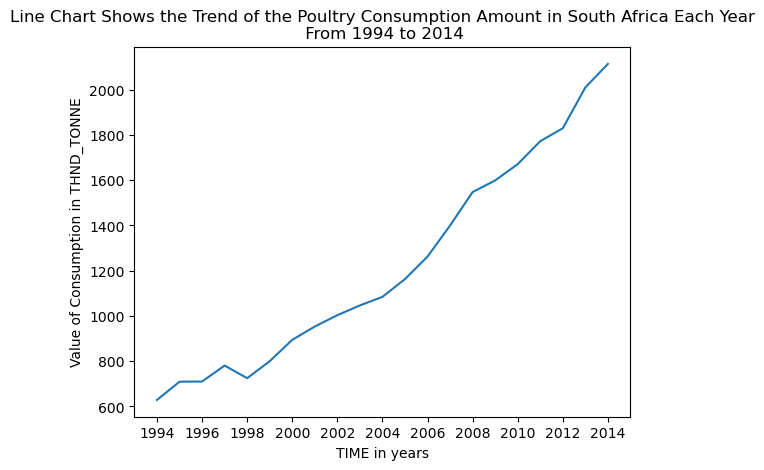

In [51]:
# visualize the Value column of the dataframe made in question 3 in a line chart, 
# set Value column as x value and time as y value
sns.lineplot(x = 'TIME', y = 'Value', data=sa_poultry_consumption_in_THND_TONNE_df,ci=None)\
.set(xlabel = "TIME in years", ylabel = "Value of Consumption in THND_TONNE",\
     title = "Line Chart Shows the Trend of \
the Poultry Consumption Amount in South Africa Each Year\
\n From 1994 to 2014")
plt.xticks(np.arange(1994, 2016, step=2)) # set the x range and step
plt.show()

The line chart shows that the amount of poultry consumption in South Africa has a trend to increase in each year.

##### Problem 6: Predict the poultry consumption for 2015 and 2016, using simple linear regression. 

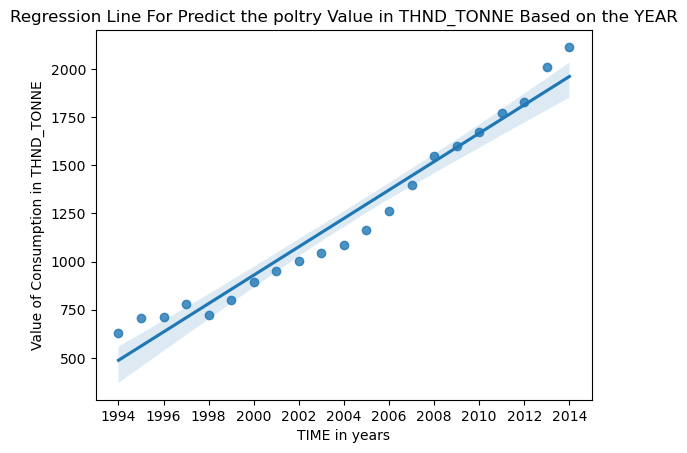

In [52]:
# build a linear regression line to predict the poltry amount in THND_TONNE consumed based on the year
sns.regplot(data=sa_poultry_consumption_in_THND_TONNE_df, x='TIME', y='Value')\
.set(xlabel = "TIME in years", ylabel = "Value of Consumption in THND_TONNE",\
     title = "Regression Line For Predict the poltry Value\
 in THND_TONNE Based on the YEAR") #display the trend line using regplot

plt.xticks(np.arange(1994, 2016, step=2)) # set the x range and step
plt.show()

In [53]:
X = sa_poultry_consumption_in_THND_TONNE_df['TIME'].to_numpy() #get the explanatory variable
X = X.reshape(-1, 1)

y = sa_poultry_consumption_in_THND_TONNE_df['Value'].to_numpy()  #get the response variable
y = y.reshape(-1, 1)

lr_model = LinearRegression(fit_intercept=True) #initialize the regression model
lr_model = lr_model.fit(X, y)                   #fit the data to the model, find the line of best fit

#display the parameters for the slope and intercept
print('The intercept is: ', round(lr_model.intercept_[0], 2))
print('The slope is: ', round(lr_model.coef_[0,0], 2))

The intercept is:  -146350.63
The slope is:  73.64


In [54]:
# make a prediction of 2015's Value of poltry consumption
num_2015 = np.array([2015]).reshape(-1, 1)
print('The predicted Value of poltry consumption in 2015:',round(lr_model.predict(num_2015)[0][0], 2))

The predicted Value of poltry consumption in 2015: 2034.06


In [55]:
# make a prediction of 2016's Value of poltry consumption
num_2016 = np.array([2016]).reshape(-1, 1)
print('The predicted Value of poltry consumption in 2016:',round(lr_model.predict(num_2016)[0][0], 2))

The predicted Value of poltry consumption in 2016: 2107.7


#### Draw the point of 2015 and 2016 on the graph

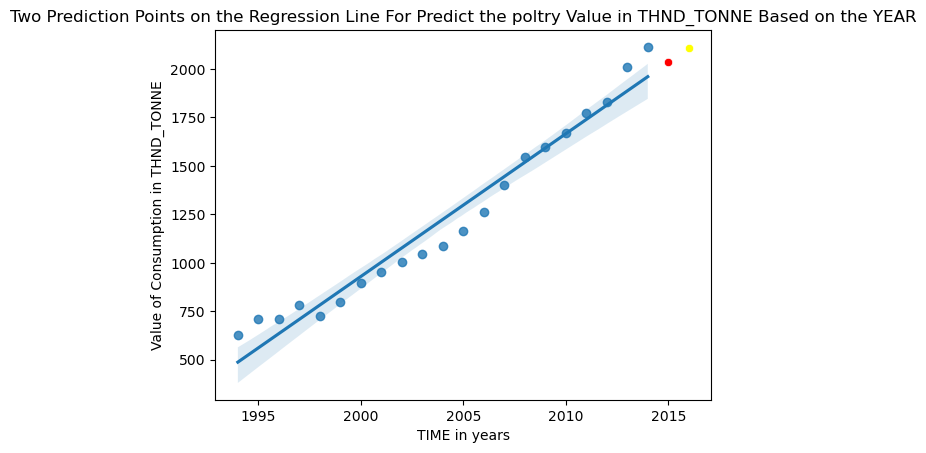

In [56]:
#visualize the prediction
fig = plt.figure()
sns.regplot(data=sa_poultry_consumption_in_THND_TONNE_df, x='TIME', y='Value')\
.set(xlabel = "TIME in years", ylabel = "Value of Consumption in THND_TONNE",\
     title = "Two Prediction Points on the Regression Line For Predict the poltry Value\
 in THND_TONNE Based on the YEAR") # draw the regression line
sns.scatterplot(x=[2015], y=[2034.06], color='red') # draw the 2015 point
sns.scatterplot(x=[2016], y=[2107.70], color='yellow') # draw the 2016 point
plt.show()

Thus, after prediction calculation from the model and visualize on the regression line, I conclude that the predicted value of poultry consumed in South Africa in 2015 is 2034.06, the predicted value of that in 2016 is 2107.70.

##### Problem 7: Calculate the R-squared and explain what this tells you about the model.

In [57]:
# calculate the r-square by using the score method on the Ir_model created before
r_sqrd = lr_model.score(X, y)
r_sqrd = round(r_sqrd, 2) # round up the r-square to 2 digits
print('r-squared is: ', r_sqrd) # print out the r-square value

r-squared is:  0.96


In this case, the coefficient of determination(r-squared) is 0.96, very close to 1. This r-squared number tells me that this regression line is a very good prediction of these data points in the dataframe. 